# Differential abundance and multiplicity

Test changes across replicate samples and compare raw and adjusted significance.

The experimental unit is a sample. Welch tests compare independent replicate log abundances feature by feature. Benjamini-Hochberg correction controls the expected false discovery proportion under its usual dependence assumptions. Ground truth is known in this simulation.

In [1]:
from pathlib import Path
import sys

here = Path.cwd()
sys.path.insert(0, str(here.parent))
import numpy as np
import matplotlib.pyplot as plt

from scipy.stats import ttest_ind, false_discovery_control

## Work through the data

The calculation prints its numerical result and plots the observations that produced it.

raw discoveries 19 BH discoveries 14 true 14 false 0


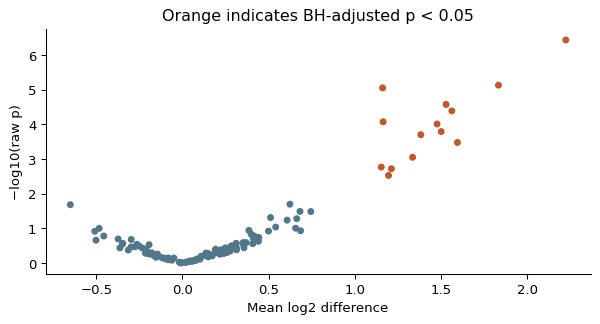

In [2]:
rng = np.random.default_rng(23)
m = 120
n = 9
effect = np.zeros(m)
effect[:18] = 1.3
base = rng.normal(12, 0.9, (m, 1))
x = base + rng.normal(0, 0.65, (m, n))
y = base + effect[:, None] + rng.normal(0, 0.65, (m, n))
p = ttest_ind(x, y, axis=1, equal_var=False).pvalue
adj = false_discovery_control(p)
calls = adj < 0.05
delta = y.mean(1) - x.mean(1)
print(
    "raw discoveries",
    sum(p < 0.05),
    "BH discoveries",
    calls.sum(),
    "true",
    sum(calls & (effect != 0)),
    "false",
    sum(calls & (effect == 0)),
)
assert np.all(adj >= p - 1e-12)
fig, ax = plt.subplots(figsize=(6.2, 3.3), constrained_layout=True)
ax.scatter(delta, -np.log10(p), c=np.where(calls, "#bf5928", "#52768a"), s=18)
ax.set(
    xlabel="Mean log2 difference",
    ylabel="−log10(raw p)",
    title="Orange indicates BH-adjusted p < 0.05",
)
plt.show()

## Interpreting the result

An observed false discovery proportion in one simulated experiment can exceed or fall below the nominal level.

## Exercise

Vary the replicate count and compare achieved sensitivity.

## References

[Benjamini and Hochberg, controlling the false discovery rate (1995)](https://doi.org/10.1111/j.2517-6161.1995.tb02031.x)